# Day 3 exercise: three conformal maps on the unit disk

Visualise the maps from the opening exercise (`day3.tex`):

1. **Joukowski:** $z = g(\zeta) = \dfrac12\left(\zeta + \dfrac1\zeta\right)$
2. $z = g(\zeta) = \dfrac{\zeta-a}{\zeta-b}\dfrac{\zeta-1/\overline{a}}{\zeta-1/\overline{b}}$
3. $z = g(\zeta) = \dfrac{|b|}{|a|}\dfrac{\zeta-a}{\zeta-b}\dfrac{\zeta-1/\overline{b}}{\zeta-1/\overline{a}}$

**Domain:** open unit disk $|\zeta|<1$ (boundary $|\zeta|=1$ shown for images). Plots use view window $[-2,2]\times[-2,2]$ in both $\zeta$- and $z$-planes.

Sample points $a$, $b$ lie in the disk (adjust below).

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PLOT_LIM = 2.0  # axes: [-PLOT_LIM, PLOT_LIM]

A = 0.5 * np.exp(1j * 0.65)
B = 0.42 * np.exp(1j * 1.55)

SAVE_FIGS = True
FIG_DIR = Path("../../teaching/text_pdf/fig").resolve()

print(f"a = {A:.4f}  (|a|={np.abs(A):.4f})")
print(f"b = {B:.4f}  (|b|={np.abs(B):.4f})")

a = 0.3980+0.3026j  (|a|=0.5000)
b = 0.0087+0.4199j  (|b|=0.4200)


## Maps and sampling helpers

In [13]:
def joukowski(z):
    z = np.asarray(z, dtype=np.complex128)
    out = np.empty_like(z)
    m = np.abs(z) > 1e-12
    out[m] = 0.5 * (z[m] + 1.0 / z[m])
    out[~m] = np.nan
    return out


def map2(z, a, b):
    z = np.asarray(z, dtype=np.complex128)
    return (z - a) / (z - b) * (z - 1 / np.conj(a)) / (z - 1 / np.conj(b))


def map3(z, a, b):
    z = np.asarray(z, dtype=np.complex128)
    s = np.abs(b) / np.abs(a)
    return s * (z - a) / (z - b) * (z - 1 / np.conj(b)) / (z - 1 / np.conj(a))


def boundary_circle(radius=1.0, n=400):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return radius * np.exp(1j * t)


def disk_grid(n_r=14, n_t=72):
    # Uniform in area on |zeta| < 1
    u = np.linspace(0, 1, n_r, endpoint=False)
    r = np.sqrt(u)
    t = np.linspace(0, 2 * np.pi, n_t, endpoint=False)
    R, T = np.meshgrid(r, t, indexing="ij")
    return (R * np.exp(1j * T)).ravel()


## Source domain in the $\zeta$-plane

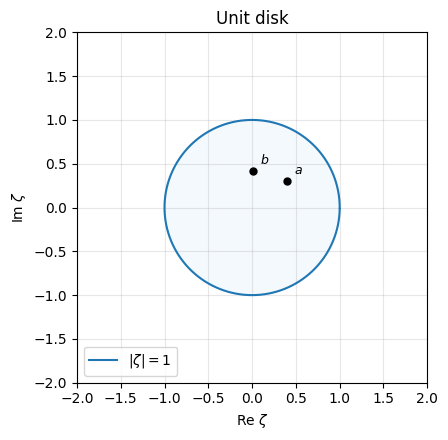

In [14]:
th = np.linspace(0, 2 * np.pi, 400, endpoint=False)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.fill(np.cos(th), np.sin(th), color="#e8f4fc", alpha=0.5)
ax.plot(np.cos(th), np.sin(th), "C0", lw=1.5, label=r"$|\zeta|=1$")
pts = [A, B]
labs = [r"$a$", r"$b$"]
for p, lab in zip(pts, labs):
    ax.plot(p.real, p.imag, "ko", ms=5)
    ax.annotate(lab, (p.real, p.imag), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_aspect("equal")
ax.set_xlim(-PLOT_LIM, PLOT_LIM)
ax.set_ylim(-PLOT_LIM, PLOT_LIM)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left")
ax.set_title("Unit disk")
ax.set_xlabel(r"Re $\zeta$")
ax.set_ylabel(r"Im $\zeta$")
plt.tight_layout()
plt.show()

## Plot images $z = g(\zeta)$ (boundaries + interior sample)

/var/folders/pb/0qtncy2d7q5cp2tqph_b7b4c0000gn/T/ipykernel_67761/3673989531.py:12: RuntimeWarning: divide by zero encountered in divide
  return (z - a) / (z - b) * (z - 1 / np.conj(a)) / (z - 1 / np.conj(b))
/var/folders/pb/0qtncy2d7q5cp2tqph_b7b4c0000gn/T/ipykernel_67761/3673989531.py:12: RuntimeWarning: invalid value encountered in multiply
  return (z - a) / (z - b) * (z - 1 / np.conj(a)) / (z - 1 / np.conj(b))
/var/folders/pb/0qtncy2d7q5cp2tqph_b7b4c0000gn/T/ipykernel_67761/3673989531.py:18: RuntimeWarning: divide by zero encountered in divide
  return s * (z - a) / (z - b) * (z - 1 / np.conj(b)) / (z - 1 / np.conj(a))
/var/folders/pb/0qtncy2d7q5cp2tqph_b7b4c0000gn/T/ipykernel_67761/3673989531.py:18: RuntimeWarning: invalid value encountered in multiply
  return s * (z - a) / (z - b) * (z - 1 / np.conj(b)) / (z - 1 / np.conj(a))


saved /Users/miyoshihiroyuki/Library/Mobile Documents/com~apple~CloudDocs/2_teaching/2026/2026Erasmus_Hungary/teaching/text_pdf/fig/day3_maps_exercise.png


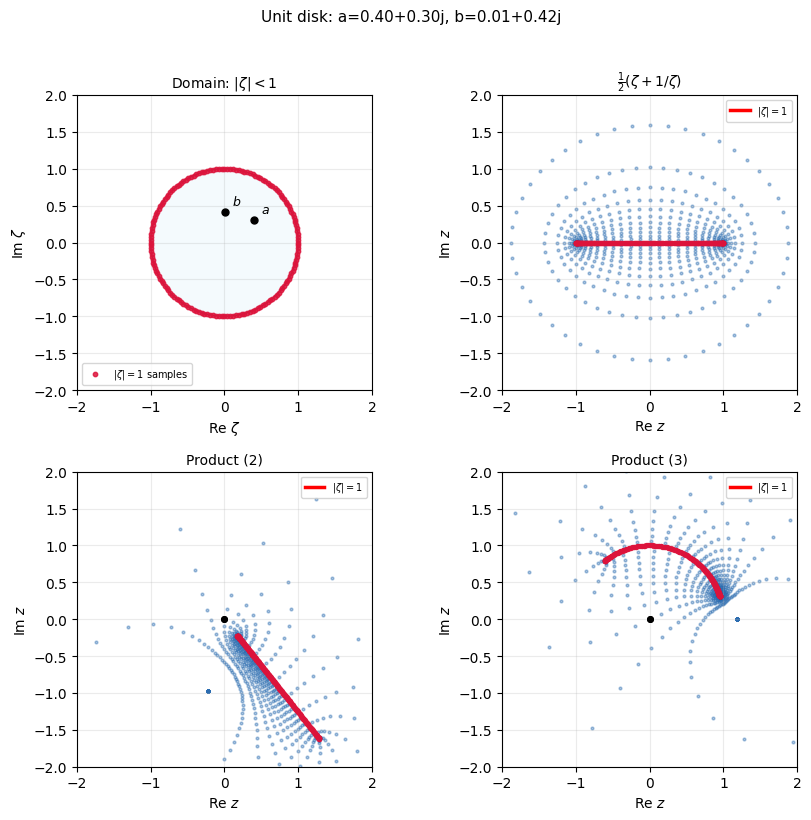

In [17]:
def plot_zeta_panel(ax, n_boundary=160):
    """Unit disk with many sample points on |zeta|=1."""
    th = np.linspace(0, 2 * np.pi, n_boundary, endpoint=False)
    z_b = np.exp(1j * th)
    ax.fill(np.cos(th), np.sin(th), color="#e8f4fc", alpha=0.45, zorder=0)
    ax.plot(np.cos(th), np.sin(th), "k-", lw=1.0, alpha=0.7, zorder=1)
    ax.scatter(z_b.real, z_b.imag, s=10, c="crimson", alpha=0.85, zorder=2, label=r"$|\zeta|=1$ samples")
    for pt, lab in [(A, "$a$"), (B, "$b$")]:
        ax.plot(pt.real, pt.imag, "ko", ms=5, zorder=3)
        ax.annotate(lab, (pt.real, pt.imag), xytext=(5, 5), textcoords="offset points", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=7, loc="lower left")
    ax.set_title(r"Domain: $|\zeta|<1$", fontsize=10)
    ax.set_xlabel(r"Re $\zeta$")
    ax.set_ylabel(r"Im $\zeta$")


def plot_image(ax, g, title, *, show_specials=True):
    z_b = boundary_circle(1.0)
    w_b = g(z_b)
    m = np.isfinite(w_b)
    wr, wi = w_b[m].real, w_b[m].imag

    z_pts = disk_grid(12, 48)
    w_pts = g(z_pts)
    ok = np.isfinite(w_pts)
    ax.scatter(w_pts[ok].real, w_pts[ok].imag, s=4, alpha=0.4, c="#2b6cb0", zorder=1)

    gap = np.hypot(wr[0] - wr[-1], wi[0] - wi[-1])
    span = max(np.hypot(wr.max() - wr.min(), wi.max() - wi.min()), 1e-9)
    if gap < 0.05 * span:
        ax.fill(wr, wi, color="red", alpha=0.28, zorder=2)
    else:
        eps = 0.035 * span
        ax.fill_between(wr, wi - eps, wi + eps, color="red", alpha=0.35, zorder=2)

    ax.plot(wr, wi, color="red", lw=2.5, zorder=3, label=r"$|\zeta|=1$")
    ax.scatter(wr, wi, s=8, c="crimson", alpha=0.75, zorder=4)

    if show_specials:
        for zp in [A, B, 1 / np.conj(A), 1 / np.conj(B)]:
            w = g(np.array([zp]))[0]
            if np.isfinite(w):
                ax.plot(w.real, w.imag, "o", ms=4, color="k", zorder=5)

    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=7, loc="upper right")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r"Re $z$")
    ax.set_ylabel(r"Im $z$")


fig, axes = plt.subplots(2, 2, figsize=(8.8, 8.0))
plot_zeta_panel(axes[0, 0])
plot_image(axes[0, 1], joukowski, r"$\frac{1}{2}(\zeta+1/\zeta)$", show_specials=False)
plot_image(axes[1, 0], lambda z: map2(z, A, B), "Product (2)")
plot_image(axes[1, 1], lambda z: map3(z, A, B), "Product (3)")
fig.suptitle(f"Unit disk: a={A:.2f}, b={B:.2f}", y=1.02, fontsize=11)
plt.tight_layout()
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / "day3_maps_exercise.png", dpi=160, bbox_inches="tight")
    print("saved", FIG_DIR / "day3_maps_exercise.png")
plt.show()



## Sanity checks on boundaries

- **Joukowski:** on $|\zeta|=1$, $g(\zeta)=\mathrm{Re}\,\zeta\in[-1,1]$ (slit on the real axis).
- **Maps (2–3):** Möbius products; compare inner/outer boundary radii or shape.

In [ ]:
z1 = boundary_circle(1.0)
w_j = joukowski(z1)
print("Joukowski on |zeta|=1:")
print(f"  Re z in [{w_j.real.min():.4f}, {w_j.real.max():.4f}]")
print(f"  max |Im z| = {np.abs(w_j.imag).max():.3e}")

for name, g in [("map2", lambda z: map2(z, A, B)), ("map3", lambda z: map3(z, A, B))]:
    w = g(z1)
    m = np.isfinite(w)
    rad = np.abs(w[m])
    print(f"{name} on |zeta|=1: |w| mean={rad.mean():.4f}, std={rad.std():.4f}")